In [1]:
!pip install langgraph langsmith langchain langchain_groq langchain_community

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 591.4/591.4 kB 11.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 39.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 38.6 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: langchain-protocol
    Found existing installation: langchain-protocol 0.0.20
    Uninstalling langchain-protocol-0.0.20:
      Successfully uninstalled langchain-protocol-0.0.20
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [langchain_community]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following

In [2]:
from typing import Annotated
from typing_extensions import TypedDict

In [3]:
!pip install wikipedia
!pip install "arxiv<2.0.0"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for wikipedia: filename=wikipedia-1.4.0-py3-none-any.whl size=11757 sha256=61defa75dad54c6d705fe00a7bf99936d515df4d55e65e72bf0e64c437e28a94
  Stored in directory: /root/.cache/pip/wheels/79/1d/c8/b64e19423cc5a2a339450ea5d145e7c8eb3d4aa2b150cde33b
Successfully built wikipedia
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [arxiv]


In [4]:
## Working With Tools

# Python 3.13 compatibility patch for legacy feedparser/arxiv packages requiring 'cgi'
import sys
try:
    import cgi
except ImportError:
    import html
    import types
    # Create a minimal mock of cgi module for feedparser
    cgi = types.ModuleType("cgi")
    cgi.escape = html.escape
    sys.modules["cgi"] = cgi

from langchain_community.utilities import ArxivAPIWrapper, WikipediaAPIWrapper
from langchain_community.tools import ArxivQueryRun, WikipediaQueryRun

## Arxiv And Wikipedia tools
arxiv_wrapper = ArxivAPIWrapper(top_k_results=1, doc_content_chars_max=300)
arxiv_tool = ArxivQueryRun(api_wrapper=arxiv_wrapper)

api_wrapper = WikipediaAPIWrapper(top_k_results=1, doc_content_chars_max=300)
wiki_tool = WikipediaQueryRun(api_wrapper=api_wrapper)

/tmp/ipykernel_877/3269323216.py:15: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import ArxivAPIWrapper, WikipediaAPIWrapper


In [5]:
wiki_tool.invoke("who is virat kohli")

'Page: Virat Kohli\nSummary: Virat Kohli (born 5 November 1988) is an Indian international cricketer and former all-format captain of the Indian national team. He is a right-handed batter and an occasional right-arm medium-pace bowler. Considered one of the greatest batters in cricket, he has been acc'

In [6]:
tools=[wiki_tool]

In [7]:
## Langgraph Application
from langgraph.graph.message import add_messages
class State(TypedDict):
  messages:Annotated[list,add_messages]

In [8]:
from langgraph.graph import StateGraph,START,END

In [9]:
graph_builder= StateGraph(State)


In [10]:
from langchain_groq import ChatGroq

In [11]:
from google.colab import userdata
groq_api_key=userdata.get("GROQ_API_KEY")

In [12]:
llm=ChatGroq(groq_api_key=groq_api_key,model_name="openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.5', 'langchain': '1.4.8', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x7c9407453e00>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x7c94071a4c20>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [13]:
llm_with_tools=llm.bind_tools(tools=tools)

In [14]:
def chatbot(state:State):
  return {"messages":[llm_with_tools.invoke(state["messages"])]}

In [15]:
from langgraph.prebuilt import ToolNode,tools_condition

In [16]:
graph_builder.add_node("chatbot",chatbot)
tool_node = ToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)

graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition,
)
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START,"chatbot")


In [17]:
graph=graph_builder.compile()

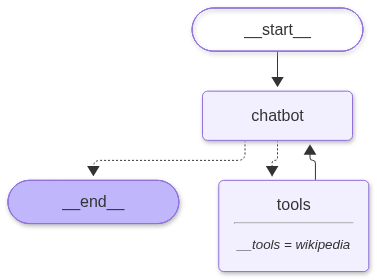

In [18]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    # This requires some extra dependencies and is optional
    pass

In [19]:
user_input="Hi there!, My name is Rajesh"

events=graph.stream(
     {"messages": [("user", user_input)]},stream_mode="values"
)

for event in events:
  event["messages"][-1].pretty_print()

================================ Human Message =================================

Hi there!, My name is Rajesh
================================== Ai Message ==================================

Hello Rajesh! Nice to meet you. How can I assist you today?


In [20]:
user_input = "what is RLHF."

# The config is the **second positional argument** to stream() or invoke()!
events = graph.stream(
    {"messages": [("user", user_input)]},stream_mode="values"
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

what is RLHF.
================================== Ai Message ==================================

**RLHF — Reinforcement Learning from Human Feedback**

Reinforcement Learning from Human Feedback (RLHF) is a training paradigm that combines reinforcement learning (RL) with guidance provided by humans rather than relying solely on a predefined reward function. It is especially popular for aligning large language models (LLMs) and other AI systems with human values, preferences, and expectations.

---

### 1. Why RLHF?
- **Hard‑to‑specify objectives:** For many tasks (e.g., generating helpful, safe, or coherent text) it’s difficult to write an explicit reward function that captures all nuances.
- **Safety & alignment:** Directly optimizing a proxy reward can produce undesirable behavior (reward hacking). Human feedback steers the model toward outcomes humans consider appropriate.
- **Data efficiency:** Humans 

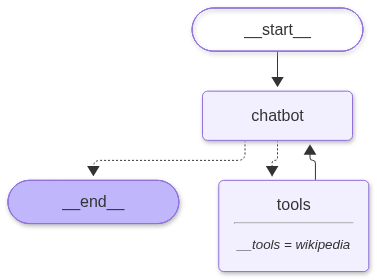

In [21]:
from IPython.display import Image, display
try:
  display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
  pass